# 1. generate the short, mid, long data file

In [2]:
import json
from transformers import BartForConditionalGeneration, BartTokenizer


/home/ywang1/miniconda3/envs/intent/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/ywang1/miniconda3/envs/intent/lib/python3.10/site-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


KeyError: 'id'

In [3]:

test_path = '/home/ywang1/data1/dataset/q2id/Q2ID_data/test_data_v10.jsonl'

# concatenate all pos docs, and calculate the token length
tokenizer = BartTokenizer.from_pretrained('facebook/bart-large')

with open(test_path, 'r') as f:
    data = [json.loads(line) for line in f]

short_id = []
mid_id = []
long_id = []

for record in data:
    pos = record['pos']
    pos_docs = ' '.join(pos)

    # calculate the token length
    token_length = len(tokenizer.encode(pos_docs))

    if token_length < 512:
        short_id.append(record['sample_id'])
    elif token_length < 1024:
        mid_id.append(record['sample_id'])
    else:
        long_id.append(record['sample_id'])

print(f'short_id: {len(short_id)}, mid_id: {len(mid_id)}, long_id: {len(long_id)}')


Token indices sequence length is longer than the specified maximum sequence length for this model (1073 > 1024). Running this sequence through the model will result in indexing errors


short_id: 215, mid_id: 24, long_id: 19


In [10]:
# long_id = [617, 496, 482, 58, 172, 524, 566, 4, 26, 94, 4598, 262, 792, 53, 3436, 217, 4139, 712, 204]
# mid_id = [1148, 1569, 2036, 3367, 772, 3976, 552, 1875, 1840, 1352, 701, 474, 4002, 871, 1295, 1310, 898, 1741, 1728, 1332, 653, 645, 3763, 355]

# ddt_ids = [58, 4, 26, 94, 53, 159, 172, 217, 204] # 9个, 有八个的pos长度超过1024， 认为是long_id， 那么认为robust的11个中有10个也是长的。 
# robust_ids = [414, 443, 257, 474, 385, 262, 458, 375, 355, 244, 260] # 11
# 所以文章中，认为long_id，有8(ddl) + 10(robust) + 11(semeval) = 29个。
# mid_id 有24(ddl) + 1(robust) + 1(semeval) = 25个。
# 剩下的是short_id：258-29-25 = 204个。


In [11]:
length = ['short', 'mid', 'long']
len_2_id = {'short': short_id, 'mid': mid_id, 'long': long_id}

for l in length:
    output_path = f'/home/ywang1/workspace/IntentRewriter/src/input_length/{l}_data.jsonl'
    with open(output_path, 'w') as f:
        for record in data:
            if record['sample_id'] in len_2_id[l]:
                f.write(json.dumps(record) + '\n')

# 2. get rouge scores
sbatch run_rouge.sh

# 3. plot the rouge scores

In [2]:
short_rouge_1 = 35.7115
short_rouge_2 = 15.3471
short_rouge_L = 26.9652 
short_bert = 64.07419919967652

mid_rouge_1 = 39.6652
mid_rouge_2 = 11.3995
mid_rouge_L = 28.2395
mid_bert = 63.75442445278168

long_rouge_1 = 33.5865
long_rouge_2 = 13.548
long_rouge_L = 28.4821
long_bert = 67.95635537097329

rouge_1 = [short_rouge_1, mid_rouge_1, long_rouge_1]
rouge_2 = [short_rouge_2, mid_rouge_2, long_rouge_2]
rouge_L = [short_rouge_L, mid_rouge_L, long_rouge_L]
bert = [short_bert, mid_bert, long_bert]

/scratch-local/69249/ipykernel_1597271/3983095020.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), font=calibri_bold, fontsize=25, fontweight='bold')  # 首先设置所有标签以确保都被访问


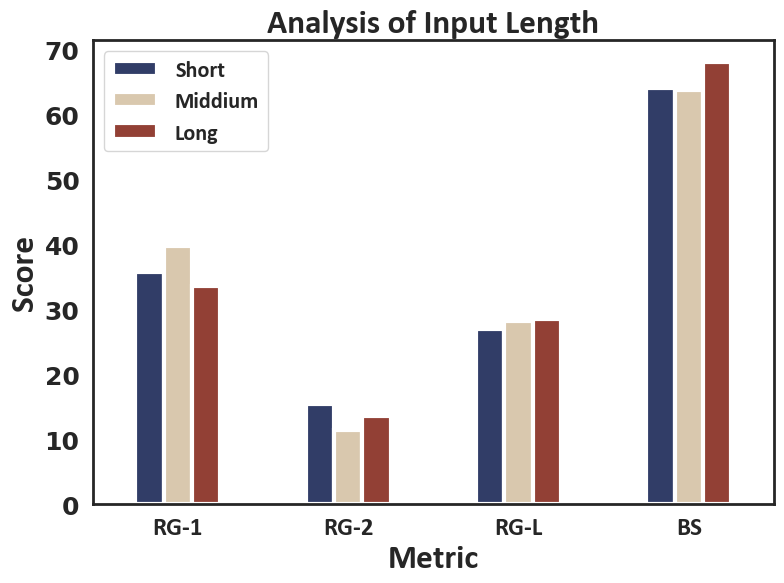

In [30]:
# use seaborn to plot the rouge scores
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib as mpl
import matplotlib
import matplotlib.font_manager as fm
font_path = '/home/ywang1/data1/font/Calibri.ttf'
font_bold_path = '/home/ywang1/data1/font/calibrib.ttf'
calibri = fm.FontProperties(fname=font_path)
calibri_bold = fm.FontProperties(fname=font_bold_path)

data = {'Metric': ['RG-1'] * 3 + ['RG-2'] * 3 + ['RG-L'] * 3 + ['BS'] * 3,
        'Length': ['Short', 'Middium', 'Long'] * 4,
        'Score': [short_rouge_1, mid_rouge_1, long_rouge_1, \
            short_rouge_2, mid_rouge_2, long_rouge_2, \
            short_rouge_L, mid_rouge_L, long_rouge_L, \
            short_bert, mid_bert, long_bert]}
df = pd.DataFrame(data)
plt.figure(figsize=(8, 6))

custom_palette = sns.color_palette(["#283870", "#E0C9A7",  "#A13425"]) #"#518DDB
# custom_palette = sns.color_palette(["#3D5C6F", "#E47159", "#F9AE78"])
# custom_palette = sns.color_palette(["#9193b4", "#bd9aad",  "#2f2d54"])
# custom_palette = sns.color_palette(["#112929", "#FCDD84",  "#C46D37"]) ##112929, #377859

# draw line chart instead of bar chart
# sns.lineplot(x="Metric", y="Score", hue="Length", data=df, palette=custom_palette)
# bar chart
sns.barplot(x="Metric", y="Score", hue="Length", data=df, width=0.5, palette=custom_palette, linewidth=3) #edgecolor='black'
# plt.ylim(0.0, 1.0)
sns.set(style="white")
# matplotlib.rcParams.update({
#     "font.family": 'Times New Roman',
#     "font.size": 25,
# })
plt.legend(loc='upper left', fontsize=16)
legend = plt.gca().get_legend()
for text in legend.get_texts():
    text.set_fontweight('bold')
ax = plt.gca()  # 获取当前的Axes对象ax
ax.set_xticklabels(ax.get_xticklabels(), font=calibri_bold, fontsize=25, fontweight='bold')  # 首先设置所有标签以确保都被访问
ax.set_xlabel('Metric', font=calibri_bold, fontweight='bold', fontsize=24)
ax.set_ylabel('Score', font=calibri_bold, fontweight='bold', fontsize=24)
# 增大轴刻度的字体大小
ax.tick_params(axis='both', labelsize=18) # 对ax1的x轴和y轴刻度标签字体大小进行调整
for label in ax.get_xticklabels():
    label.set_fontweight('bold')
for label in ax.get_yticklabels():
    label.set_fontweight('bold')
ax.set_title('Analysis of Input Length', font=calibri_bold, fontweight='bold', fontsize=24)
# plt.title("Games", fontweight='bold', fontsize=24)
# matplotlib.rcParams.update({
#     "font.family": 'Times New Roman',
#     "font.size": 25,
# })
legend = ax.get_legend()  
legend.set_title(None)
# 设置边线宽度
for spine in ax.spines.values():
    spine.set_linewidth(2)  # Set the spine line width to 2
for text in legend.get_texts():
    text.set_fontproperties(calibri_bold)
    text.set_fontweight('bold')
    text.set_fontsize(16)
plt.tight_layout()
plt.savefig("plot_input_length.pdf")

plt.show()

# times new roman

/scratch-local/69249/ipykernel_3990547/1619756855.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), font=times_new_roman_bold, fontsize=25, fontweight='bold')  # 首先设置所有标签以确保都被访问
/scratch-local/69249/ipykernel_3990547/1619756855.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), font=times_new_roman_bold, fontsize=25, fontweight='bold')


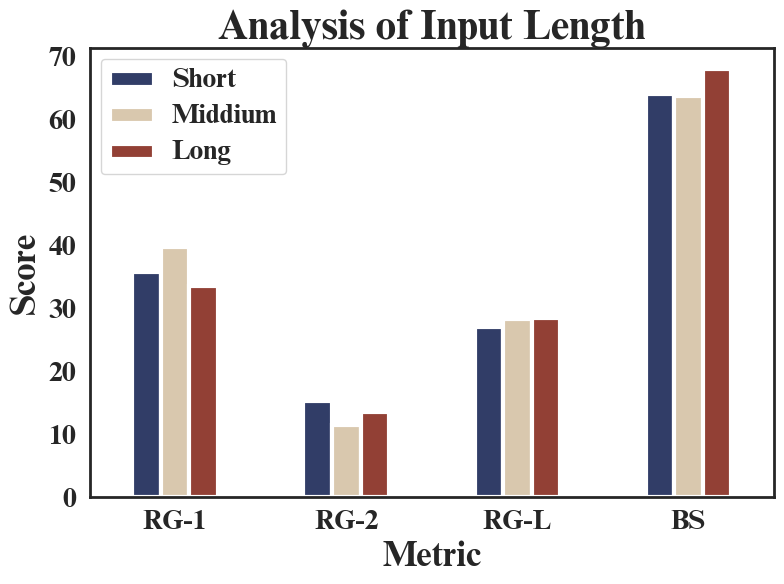

In [4]:
# use seaborn to plot the rouge scores
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib as mpl
import matplotlib
import matplotlib.font_manager as fm
font_path = '/home/ywang1/data1/font/times new roman.ttf'
font_bold_path = '/home/ywang1/data1/font/times new roman bold.ttf'
times_new_roman = fm.FontProperties(fname=font_path)
times_new_roman_bold = fm.FontProperties(fname=font_bold_path)

data = {'Metric': ['RG-1'] * 3 + ['RG-2'] * 3 + ['RG-L'] * 3 + ['BS'] * 3,
        'Length': ['Short', 'Middium', 'Long'] * 4,
        'Score': [short_rouge_1, mid_rouge_1, long_rouge_1, \
            short_rouge_2, mid_rouge_2, long_rouge_2, \
            short_rouge_L, mid_rouge_L, long_rouge_L, \
            short_bert, mid_bert, long_bert]}
df = pd.DataFrame(data)
plt.figure(figsize=(8, 6))

custom_palette = sns.color_palette(["#283870", "#E0C9A7",  "#A13425"]) #"#518DDB
# custom_palette = sns.color_palette(["#3D5C6F", "#E47159", "#F9AE78"])
# custom_palette = sns.color_palette(["#9193b4", "#bd9aad",  "#2f2d54"])
# custom_palette = sns.color_palette(["#112929", "#FCDD84",  "#C46D37"]) ##112929, #377859

# draw line chart instead of bar chart
# sns.lineplot(x="Metric", y="Score", hue="Length", data=df, palette=custom_palette)
# bar chart
sns.barplot(x="Metric", y="Score", hue="Length", data=df, width=0.5, palette=custom_palette, linewidth=3) #edgecolor='black'
# plt.ylim(0.0, 1.0)
sns.set(style="white")
# matplotlib.rcParams.update({
#     "font.family": 'Times New Roman',
#     "font.size": 25,
# })
plt.legend(loc='upper left', fontsize=16)
legend = plt.gca().get_legend()
for text in legend.get_texts():
    text.set_fontweight('bold')
ax = plt.gca()  # 获取当前的Axes对象ax
ax.set_xticklabels(ax.get_xticklabels(), font=times_new_roman_bold, fontsize=25, fontweight='bold')  # 首先设置所有标签以确保都被访问
ax.set_yticklabels(ax.get_yticklabels(), font=times_new_roman_bold, fontsize=25, fontweight='bold')
ax.set_xlabel('Metric', font=times_new_roman_bold, fontweight='bold', fontsize=25)
ax.set_ylabel('Score', font=times_new_roman_bold, fontweight='bold', fontsize=25)
# 增大轴刻度的字体大小
ax.tick_params(axis='both', labelsize=20) # 对ax1的x轴和y轴刻度标签字体大小进行调整
for label in ax.get_xticklabels():
    label.set_fontweight('bold')
for label in ax.get_yticklabels():
    label.set_fontweight('bold')
ax.set_title('Analysis of Input Length', font=times_new_roman_bold, fontweight='bold', fontsize=30)
# plt.title("Games", fontweight='bold', fontsize=24)
# matplotlib.rcParams.update({
#     "font.family": 'Times New Roman',
#     "font.size": 25,
# })
legend = ax.get_legend()  
legend.set_title(None)
# 设置边线宽度
for spine in ax.spines.values():
    spine.set_linewidth(2)  # Set the spine line width to 2
for text in legend.get_texts():
    text.set_fontproperties(times_new_roman_bold)
    text.set_fontweight('bold')
    text.set_fontsize(20)
plt.tight_layout()
plt.savefig("plot_input_length.pdf")

plt.show()